# Gesture pattern similarity

Loads the saved calibration (`calibration.json`, format 5) and builds the cosine-similarity
matrix between the seven learned gesture patterns. Each pattern is a gesture's template across
the 8 channels, in rest standard deviations (`templates` in `src/emg/gesture.rs`). Pairs whose
patterns point the same way are the ones the NNLS decoder mixes up.

Needs `numpy` and `matplotlib`.

In [9]:
import base64, json, struct
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

CALIBRATION = Path('../calibration.json')
NAMES = ['Rotate in', 'Rotate out', 'Tricep', 'Bicep', 'Wrist back', 'Wrist curl', 'Grip']
NUM_CHANNELS, NUM_GESTURES = 8, len(NAMES)

## Read the saved calibration

The `calibration` field is base64 of a bincode-serialized `SavedCalibration` (`src/lib.rs`).
This reads its muscle-scheme part up to the templates and skips the finger scheme.

In [10]:
class Reader:
    def __init__(self, buf):
        self.buf, self.pos = buf, 0

    def take(self, fmt):
        vals = struct.unpack_from('<' + fmt, self.buf, self.pos)
        self.pos += struct.calcsize('<' + fmt)
        return vals

    def u8(self): return self.take('B')[0]
    def u64(self): return self.take('Q')[0]
    def features(self): return np.array(self.take(f'{NUM_CHANNELS}d'))
    def option(self, read): return read() if self.u8() else None
    def vec(self, read): return [read() for _ in range(self.u64())]


def load_gesture_calibration(path):
    r = Reader(base64.b64decode(json.loads(path.read_text())['calibration']))
    (version,) = r.take('I')
    assert version == 5, f'calibration format {version}; this notebook reads format 5'
    rest = r.option(lambda: {'mean': r.features(), 'scale': r.features(),
                             'seen': np.array(r.take(f'{NUM_CHANNELS}B'), dtype=bool)})
    r.vec(r.features)                          # postures
    r.vec(lambda: r.vec(r.features))           # posture_rest
    for _ in range(NUM_GESTURES):              # data: hard, hard_rec, medium, shapes
        r.option(r.features); r.vec(r.features); r.vec(r.features); r.vec(r.features)
    templates = [r.option(r.features) for _ in range(NUM_GESTURES)]
    return rest, templates


rest, templates = load_gesture_calibration(CALIBRATION)
calibrated = [g for g, t in enumerate(templates) if t is not None]
seen = rest['seen']
names = [NAMES[g] for g in calibrated]
patterns = np.array([templates[g] for g in calibrated]) * seen   # channels without contact left out
print(f'{len(calibrated)} calibrated gestures, {seen.sum()} of {NUM_CHANNELS} channels in contact')

7 calibrated gestures, 8 of 8 channels in contact


## Extrapolating which muscle is on which channel 

Electrodes can go on any channel, so the app doesn't record which muscle each one is on.
These guesses come from which gesture each channel responds to most in the patterns below:

| Channel | Guess | Why |
|---|---|---|
| Ch1 | pronator teres | strongest in rotate in, nearly as strong in wrist curl (the flexors sit next to it) |
| Ch2 | supinator | weak overall, peaks in rotate out |
| Ch3 | wrist flexors | weak, peaks in grip and wrist curl |
| Ch4 | finger flexors | dominant in grip |
| Ch5 | biceps | only bicep curl lights it up |
| Ch6 | wrist extensors | peaks in wrist back |
| Ch7 | triceps | only tricep extend lights it up |
| Ch8 | brachioradialis | the one left over, but it's high in every gesture and highest in tricep extend, which the brachioradialis shouldn't be. It may be off-site or picking up crosstalk. |

In [11]:
CHANNEL_GUESS = ['pronator teres', 'supinator', 'wrist flexors', 'finger flexors',
                 'biceps', 'wrist extensors', 'triceps', 'brachioradialis']
channel_labels = [f'Ch{c + 1} · {m}?' for c, m in enumerate(CHANNEL_GUESS)]

## Gesture patterns

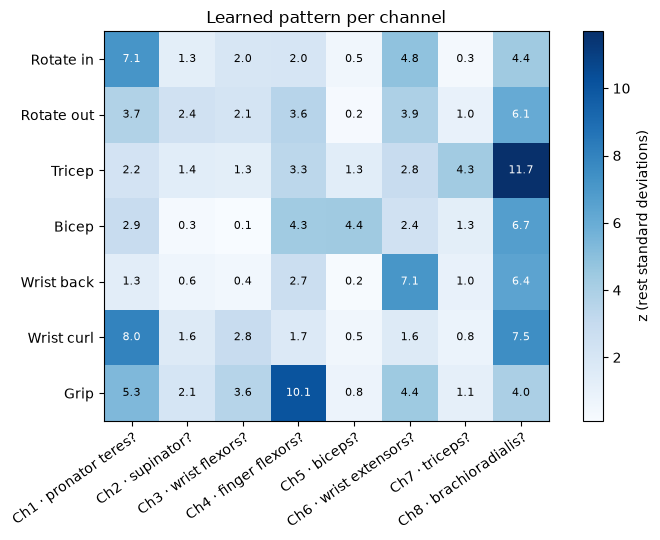

In [12]:
fig, ax = plt.subplots(figsize=(8, 5.5))
im = ax.imshow(patterns, cmap='Blues')
ax.set_xticks(range(NUM_CHANNELS), channel_labels, rotation=35, ha='right', rotation_mode='anchor')
ax.set_yticks(range(len(names)), names)
for (i, c), v in np.ndenumerate(patterns):
    ax.text(c, i, f'{v:.1f}', ha='center', va='center', fontsize=8,
            color='white' if v > patterns.max() / 2 else 'black')
fig.colorbar(im, ax=ax, label='z (rest standard deviations)')
ax.set_title('Learned pattern per channel')
fig.tight_layout()

## Similarity matrix

Cosine similarity between every pair of patterns: 1 means they point the same way, 0 means
they share no channels. All patterns are non-negative, so it never goes below 0.

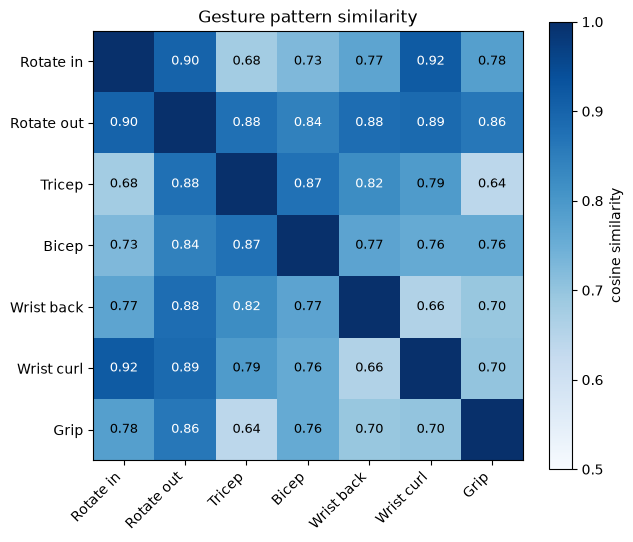

In [13]:
units = patterns / np.linalg.norm(patterns, axis=1, keepdims=True)
similarity = units @ units.T

fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(similarity, cmap='Blues', vmin=0.5, vmax=1)
ax.set_xticks(range(len(names)), names, rotation=45, ha='right')
ax.set_yticks(range(len(names)), names)
for (i, j), v in np.ndenumerate(similarity):
    if i != j:
        ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=9,
                color='white' if v > 0.8 else 'black')
fig.colorbar(im, ax=ax, label='cosine similarity')
ax.set_title('Gesture pattern similarity')
fig.tight_layout()

In [14]:
pairs = sorted(((similarity[i, j], names[i], names[j])
                for i in range(len(names)) for j in range(i + 1, len(names))), reverse=True)
print('Most alike pairs:')
for s, a, b in pairs[:5]:
    print(f'  {a:>10} / {b:<10} {s:.3f}')

Most alike pairs:
   Rotate in / Wrist curl 0.917
   Rotate in / Rotate out 0.902
  Rotate out / Wrist curl 0.888
  Rotate out / Wrist back 0.881
  Rotate out / Tricep     0.875


## The matrix the decoder solves against

`A` is the pattern matrix plotted above (one column per gesture, one row per channel, with the
muscle guesses). Each sample, the decoder solves NNLS in normal-equation form against `G = AᵀA` over the usable
channels, with each diagonal entry scaled by `1 + GESTURE_RIDGE` (`fit_patterns` in
`src/emg/gesture.rs`). The similarity matrix above is this matrix normalized by the pattern sizes.

In [15]:
GESTURE_RIDGE = 0.02
G = patterns @ patterns.T
G[np.diag_indices_from(G)] *= 1 + GESTURE_RIDGE
np.set_printoptions(precision=1, suppress=True, linewidth=120)
print(G)

[[105.9  87.1  94.   73.5  79.2 109.5 108.2]
 [ 87.1  91.6 112.7  79.3  84.3  98.6 111.2]
 [ 94.  112.7 188.3 117.9 112.7 125.9 118.3]
 [ 73.5  79.3 117.9 100.7  77.5  88.4 102.4]
 [ 79.2  84.3 112.7  77.5 103.8  77.7  95.3]
 [109.5  98.6 125.9  88.4  77.7 140.  111.6]
 [108.2 111.2 118.3 102.4  95.3 111.6 188.4]]
